In [ ]:
spark.stop()

In [ ]:
# Remove Colab's Spark Connect package that requires PySpark 4.x
!pip uninstall -y dataproc-spark-connect

# Install Java 17
!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless -qq

# Tell this runtime to use Java 17
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

# Remove the currently installed PySpark version
!pip uninstall -y pyspark py4j

# Install the REQUIRED version
!pip install -q --no-cache-dir pyspark==3.5.1

Found existing installation: dataproc-spark-connect 1.1.0
Uninstalling dataproc-spark-connect-1.1.0:
  Successfully uninstalled dataproc-spark-connect-1.1.0
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122807 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.20.1+1-1~24.04_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.20.1+1-1~24.04) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.20.1+1-1~24.04_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.20.1+1-1~24.04) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.20.1+1-1~24.04) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.001s][warning

In [ ]:
import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

!java -version

[0.022s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.022s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [ ]:
import pyspark

print("PySpark version:", pyspark.__version__)

PySpark version: 4.0.4


In [ ]:
import os
# Programmatically restart the Colab runtime
os.kill(os.getpid(), 9)

In [ ]:
# 1. Delete the corrupted Spark folder and tgz from the failed download
!rm -rf /content/spark-3.5.1-bin-hadoop3
!rm -f /content/spark-3.5.1-bin-hadoop3.tgz

# 2. Ensure the conflicting package is gone
!pip uninstall -y dataproc-spark-connect pyspark > /dev/null 2>&1

# 3. Install PySpark 3.5.1 via pip (this is fast and reliable)
!pip install -q pyspark==3.5.1
!pip install -q findspark

# 4. Start Spark WITHOUT pointing SPARK_HOME to a broken folder
import os
# Clear any broken SPARK_HOME
if "SPARK_HOME" in os.environ:
    del os.environ["SPARK_HOME"]
# Set JAVA_HOME to 17
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

import findspark
# Let findspark automatically find the pip-installed PySpark
findspark.init()

from pyspark.sql import SparkSession
import pyspark

# 5. Start the session
spark = SparkSession.builder.master("local[*]").appName("RetailMart_Pip").getOrCreate()

print(f" PySpark version: {pyspark.__version__}")
print(" Spark session created successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.0/317.0 MB 1.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.5/200.5 kB 12.8 MB/s eta 0:00:00
✅ PySpark version: 3.5.1
✅ Spark session created successfully!


In [ ]:
import os
import glob
import pandas as pd

# 1. Ensure Drive is mounted
from google.colab import drive
drive.mount('/content/drive')

print("Searching for your new shortcut folder...")
# 2. Automatically find the exact path of the new folder
search_path = glob.glob("/content/drive/MyDrive/Data Mining/Visualization_Notebook*/cleaned_retailmart.parquet")

if not search_path:
    print(" Could not find the folder. Did you create the shortcut inside 'Data Mining'?")
else:
    folder_path = search_path[0]
    print(f" Found folder at: {folder_path}")

    # 3. Get all files in the folder
    all_files = glob.glob(f"{folder_path}/*")
    valid_files = []

    for f in all_files:
        filename = os.path.basename(f)
        # Keep only actual parquet data files, ignore hidden .crc and _SUCCESS files
        if "part-" in filename and not filename.startswith(".") and filename.endswith(".parquet"):
            size_mb = os.path.getsize(f) / (1024 * 1024)
            if size_mb > 0:
                print(f" Valid file: {filename} ({size_mb:.2f} MB)")
                valid_files.append(f)

    if len(valid_files) == 0:
        print(" No valid data files found. The engineer's upload might still be broken.")
    else:
        print(f"\nReading {len(valid_files)} files directly from the cloud using Spark...")

        # 4. Spark reads the distributed files
        df_spark = spark.read.parquet(*valid_files)

        print("Removing duplicates (from the 36M row bug)...")
        df_clean = df_spark.dropDuplicates(["transaction_id"])

        print("Converting to Pandas...")
        df_txn = df_clean.toPandas()

        print(f" SUCCESS! FULL DATASET READY: {len(df_txn):,} rows.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Searching for your new shortcut folder...
✅ Found folder at: /content/drive/MyDrive/Data Mining/Visualization_Notebook_&_Tableau_Dashboard /cleaned_retailmart.parquet
✅ Valid file: part-00002-00d95ab5-f1d7-4dba-9bf5-797f006dbd20-c000.snappy.parquet (10.31 MB)
✅ Valid file: part-00000-00d95ab5-f1d7-4dba-9bf5-797f006dbd20-c000.snappy.parquet (22.39 MB)
✅ Valid file: part-00001-00d95ab5-f1d7-4dba-9bf5-797f006dbd20-c000.snappy.parquet (22.18 MB)

Reading 3 files directly from the cloud using Spark...
Removing duplicates (from the 36M row bug)...
Converting to Pandas...
🎉 SUCCESS! FULL DATASET READY: 920,864 rows.


In [ ]:
df_txn.to_csv('tableau_data.csv', index=False)
from google.colab import files
files.download('tableau_data.csv')
print(" CSV downloaded! Open this in Tableau Public.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 CSV downloaded! Open this in Tableau Public.


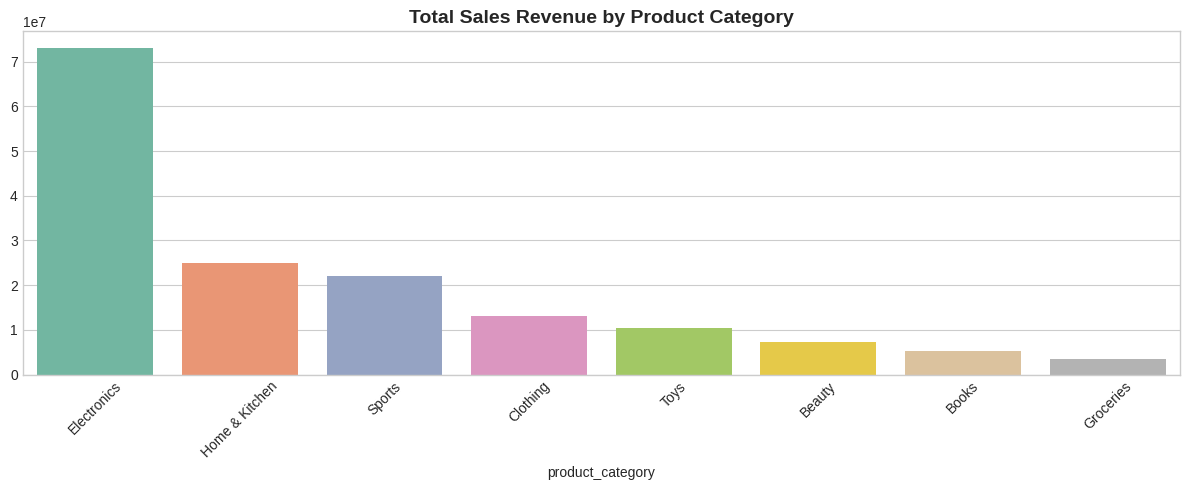

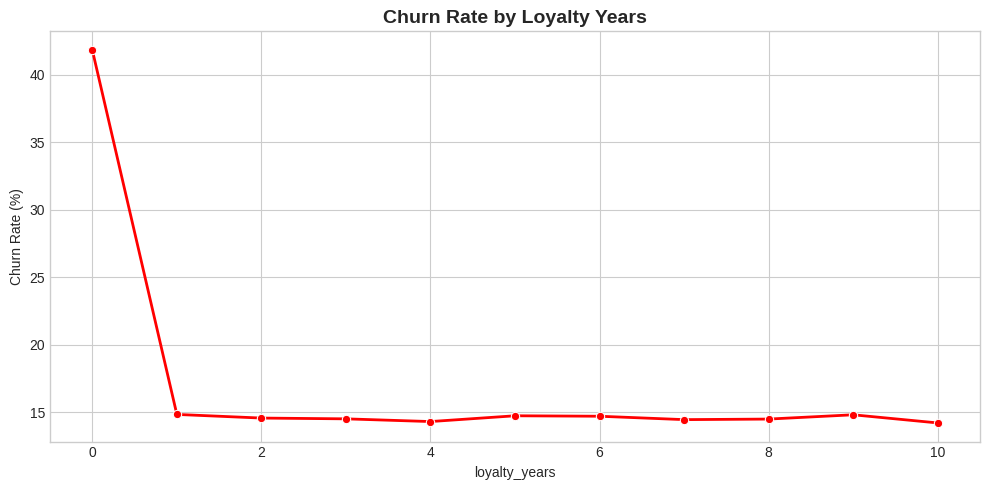

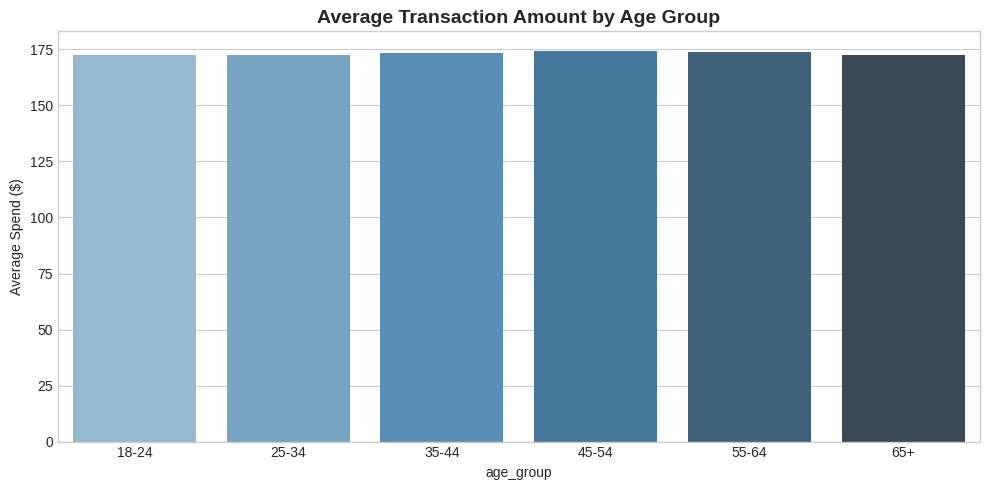

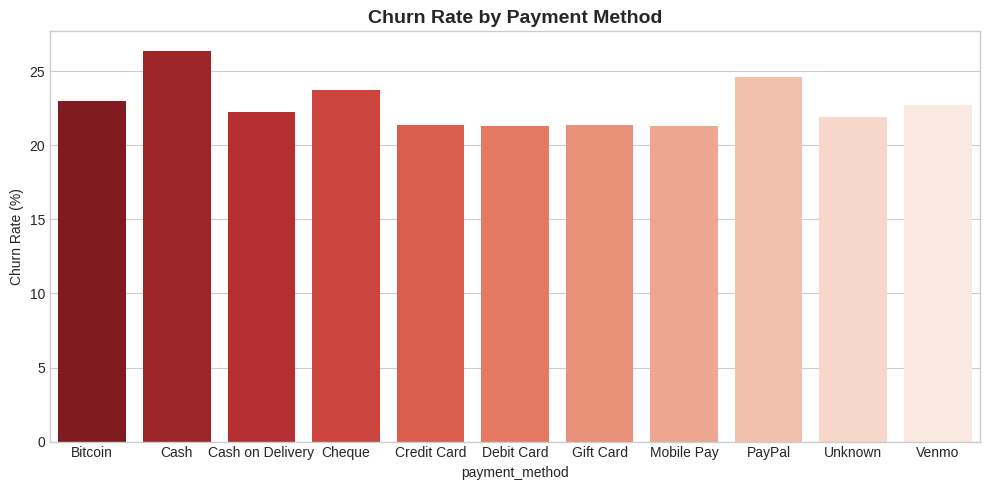

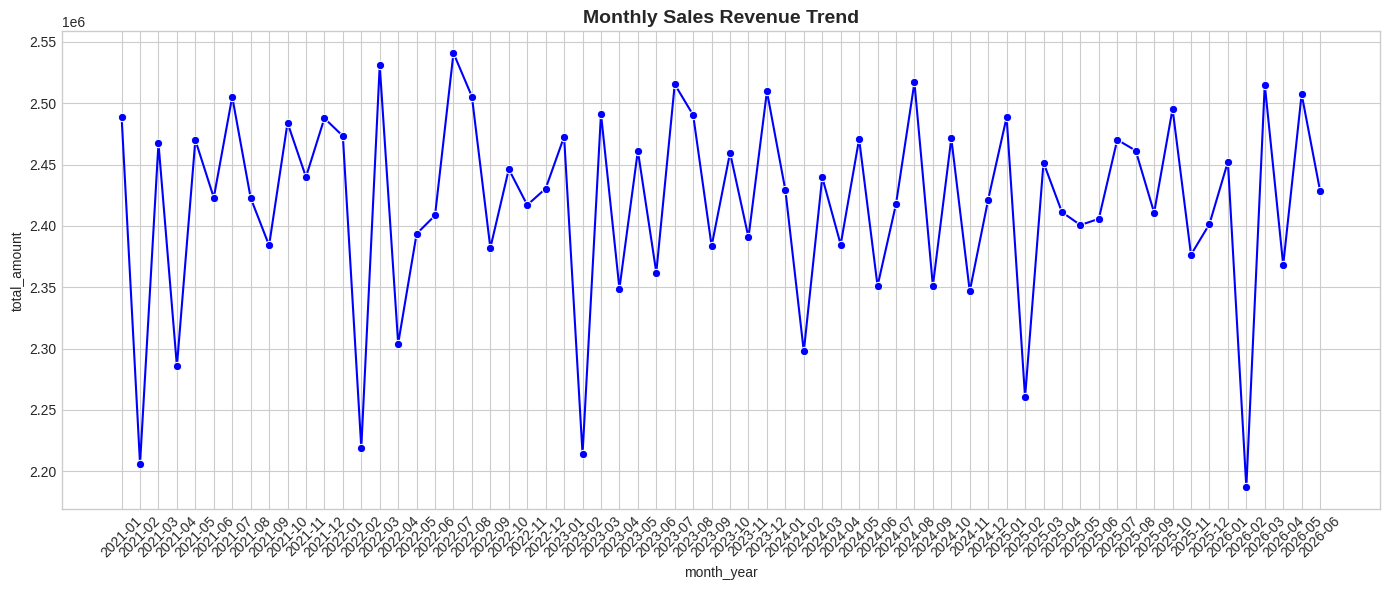

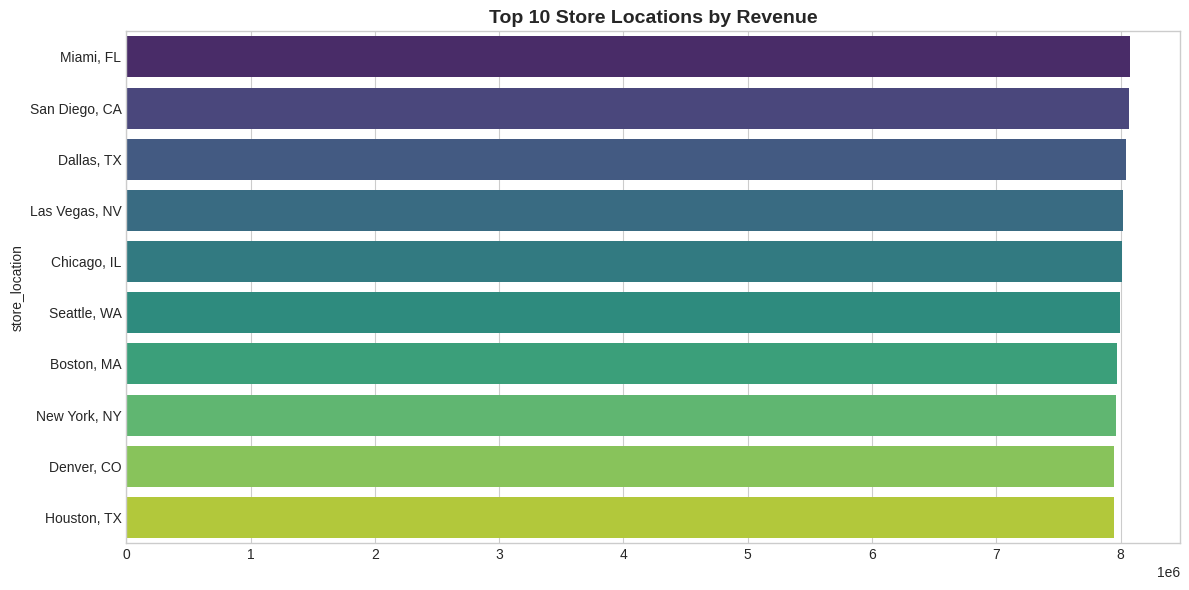

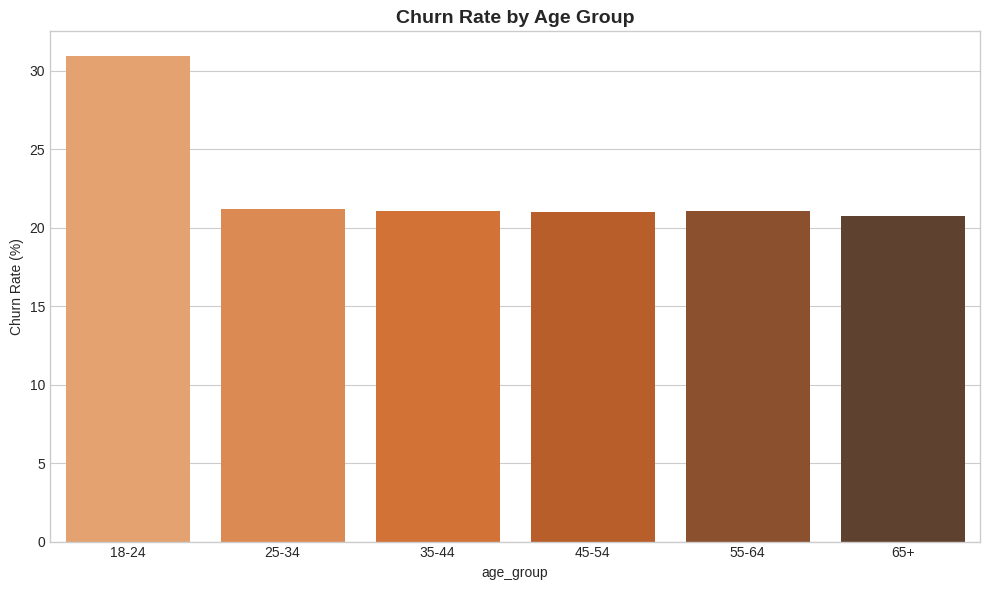

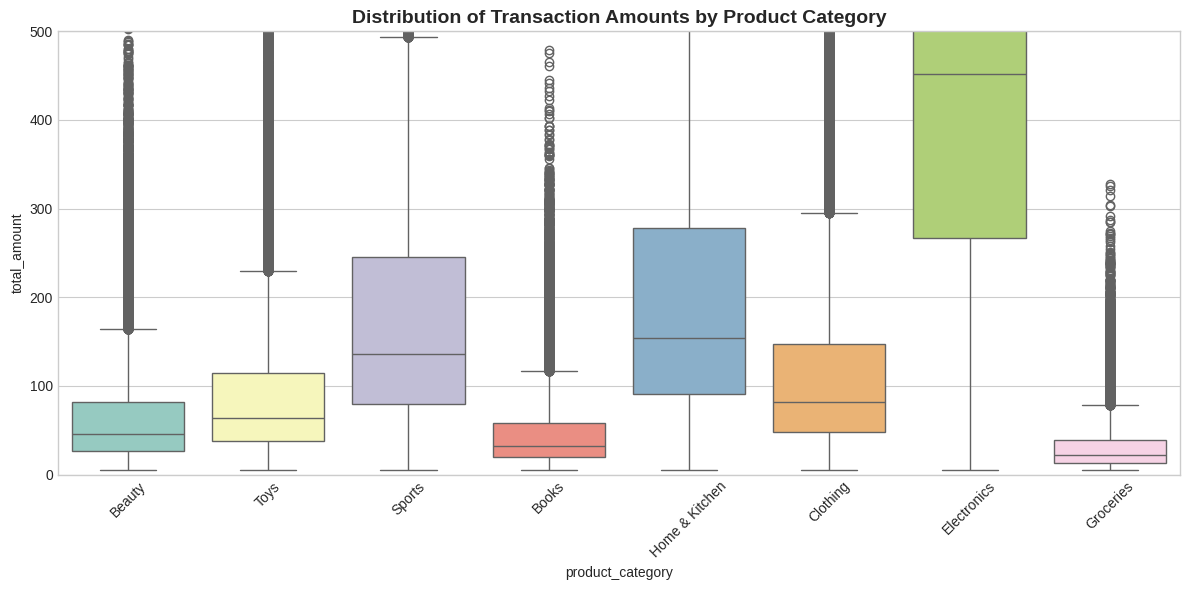

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

# Convert date to datetime for time series chart
df_txn['transaction_date'] = pd.to_datetime(df_txn['transaction_date'])
df_txn['month_year'] = df_txn['transaction_date'].dt.to_period('M').astype(str)

# CHART 1: Sales by Product Category
plt.figure(figsize=(12, 5))
category_sales = df_txn.groupby('product_category')['total_amount'].sum().sort_values(ascending=False)
sns.barplot(x=category_sales.index, y=category_sales.values, hue=category_sales.index, legend=False)
plt.title('Total Sales Revenue by Product Category', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# CHART 2: Churn Rate by Loyalty Years
plt.figure(figsize=(10, 5))
churn_by_loyalty = df_txn.groupby('loyalty_years')['churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
sns.lineplot(data=churn_by_loyalty, x='loyalty_years', y='churn', marker='o', color='red', linewidth=2)
plt.title('Churn Rate by Loyalty Years', fontsize=14, fontweight='bold')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

# CHART 3: Average Spend by Age Group
bins = [18, 25, 35, 45, 55, 65, 85]
labels = ['18-24', '25-34', '35-44', '45-54', '55-64', '65+']
df_txn['age_group'] = pd.cut(df_txn['customer_age'], bins=bins, labels=labels, right=False)
plt.figure(figsize=(10, 5))
avg_spend = df_txn.groupby('age_group', observed=False)['total_amount'].mean().reset_index()
sns.barplot(data=avg_spend, x='age_group', y='total_amount', hue='age_group', palette='Blues_d', legend=False)
plt.title('Average Transaction Amount by Age Group', fontsize=14, fontweight='bold')
plt.ylabel('Average Spend ($)')
plt.tight_layout()
plt.show()

# CHART 4: Churn Rate by Payment Method
plt.figure(figsize=(10, 5))
churn_payment = df_txn.groupby('payment_method')['churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
sns.barplot(data=churn_payment, x='payment_method', y='churn', hue='payment_method', palette='Reds_r', legend=False)
plt.title('Churn Rate by Payment Method', fontsize=14, fontweight='bold')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

# CHART 5: Monthly Sales Trend
monthly_sales = df_txn.groupby('month_year')['total_amount'].sum().reset_index()
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_sales, x='month_year', y='total_amount', marker='o', color='b')
plt.title('Monthly Sales Revenue Trend', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# CHART 6: Top 10 Store Locations by Revenue
plt.figure(figsize=(12, 6))
store_sales = df_txn.groupby('store_location')['total_amount'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=store_sales.values, y=store_sales.index, hue=store_sales.index, palette='viridis', legend=False)
plt.title('Top 10 Store Locations by Revenue', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# CHART 7: Churn Rate by Age Group
plt.figure(figsize=(10, 6))
churn_age = df_txn.groupby('age_group', observed=False)['churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
sns.barplot(data=churn_age, x='age_group', y='churn', hue='age_group', palette='Oranges_d', legend=False)
plt.title('Churn Rate by Age Group', fontsize=14, fontweight='bold')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.show()

# CHART 8: Distribution of Transaction Amounts
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_txn, x='product_category', y='total_amount', hue='product_category', palette='Set3', legend=False)
plt.title('Distribution of Transaction Amounts by Product Category', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.ylim(0, 500)
plt.tight_layout()
plt.show()